In [15]:
import numpy as np
import matplotlib.pyplot as plt
import json
import pandas as pd
import os
import re
from pythainlp import word_tokenize

In [16]:
def entity_figure(
    df,
    label_col="label",
    figsize=(14, 8),
    min_display_frac=0.01,
    panel_a_as_percent=True,
    sort_desc=True,
    save_path=None
):
    """
    Create a two-panel figure:
      Panel A: overall proportion of each entity type
      Panel B: 100% stacked bar chart of semantic-tag composition within each entity type

    Parameters
    ----------
    df : pd.DataFrame
        Input dataframe where:
        - label_col = entity type
        - all other columns = semantic tag counts
    label_col : str
        Column containing entity type labels
    figsize : tuple
        Figure size
    min_display_frac : float
        Minimum within-row fraction to annotate in Panel B
    panel_a_as_percent : bool
        If True, Panel A x-axis is shown as percentages
    sort_desc : bool
        If True, sort entity types by total count descending
    save_path : str or None
        If provided, save figure to this path
    """

    # ---- prepare data ----
    cols = [c for c in df.columns if c != label_col]
    plot_df = df.copy()

    # total count per entity type
    plot_df["total"] = plot_df[cols].sum(axis=1)

    # remove rows with zero total
    plot_df = plot_df.loc[plot_df["total"] > 0].copy()

    # sort by total count
    if sort_desc:
        plot_df = plot_df.sort_values("total", ascending=False).reset_index(drop=True)

    entity_labels = plot_df[label_col].tolist()
    entity_totals = plot_df["total"].to_numpy()
    grand_total = entity_totals.sum()
    entity_props = entity_totals / grand_total

    # proportions within each entity type for panel B
    prop_df = plot_df[cols].div(plot_df["total"], axis=0)

    # color map for semantic tags
    cmap = plt.get_cmap("tab20")
    col_to_color = {c: cmap(i % cmap.N) for i, c in enumerate(cols)}

    # ---- figure layout ----
    fig, (ax1, ax2) = plt.subplots(
        ncols=2,
        figsize=figsize,
        gridspec_kw={"width_ratios": [1.0, 1.8]}
    )

    # =========================
    # Panel A: entity type distribution
    # =========================
    y = np.arange(len(entity_labels))

    if panel_a_as_percent:
        panel_a_vals = entity_props * 100
        xlabel_a = "Proportion of all entities (%)"
    else:
        panel_a_vals = entity_totals
        xlabel_a = "Number of entities"

    bars = ax1.barh(y, panel_a_vals)

    ax1.set_yticks(y)
    ax1.set_yticklabels(entity_labels)
    ax1.invert_yaxis()  # top = largest
    ax1.set_xlabel(xlabel_a)
    ax1.set_title("A. Overall distribution of entity domains")

    # annotate count + percent
    for i, (bar, count, prop) in enumerate(zip(bars, entity_totals, entity_props)):
        x = bar.get_width()
        txt = f"n={count:,} ({prop*100:.2f}%)"
        pad = max(panel_a_vals) * 0.01
        ax1.text(x + pad, bar.get_y() + bar.get_height()/2, txt,
                 va="center", fontsize=9)
    ax1.set_xlim(0, max(panel_a_vals) * 1.35)

    # =========================
    # Panel B: 100% stacked composition
    # =========================
    left = np.zeros(len(plot_df))

    for c in cols:
        vals = prop_df[c].to_numpy()
        bars = ax2.barh(
            y,
            vals,
            left=left,
            label=c,
        )

        for i, (v, lft) in enumerate(zip(vals, left)):
            if v >= min_display_frac:
                ax2.text(
                    lft + v / 2,
                    i,
                    f"{v*100:.2f}%",
                    ha="center",
                    va="center",
                    fontsize=8
                )
        left += vals

    ax2.set_yticks(y)
    ax2.set_yticklabels(entity_labels)
    ax2.invert_yaxis()
    ax2.set_xlim(0, 1)
    ax2.set_xlabel("Semantic-tag composition within entity domain")
    ax2.set_title("B. Semantic-tag composition within each entity domain")

    # x-axis as percentages
    xticks = np.linspace(0, 1, 6)
    ax2.set_xticks(xticks)
    ax2.set_xticklabels([f"{int(x*100)}%" for x in xticks])

    # legend
    handles = [
        plt.Line2D([0], [0], marker='s', linestyle='',
                   markerfacecolor=col_to_color[c], markeredgecolor=col_to_color[c],
                   markersize=10, label=c)
        for c in cols
    ]
    # recolor plotted bars to match legend
    for container, c in zip(ax2.containers, cols):
        for patch in container:
            patch.set_facecolor(col_to_color[c])
            patch.set_edgecolor("white")
            patch.set_linewidth(0.8)

    ax2.legend(
        handles=handles,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False,
        title="Semantic tag"
    )

    # style
    for ax in (ax1, ax2):
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

In [17]:
dataset_path = r"C:\Users\Natt\thesis\DATA\goldens.json"  # Update this to your actual dataset path

if not os.path.exists(dataset_path):
    raise FileNotFoundError(f"Dataset file not found: {dataset_path}")

if os.path.getsize(dataset_path) == 0:
    raise ValueError(f"Dataset file is empty: {dataset_path}")

with open(dataset_path, 'r', encoding='utf-8') as f:
    data = json.load(f)

if not isinstance(data, list):
    raise TypeError("Expected a top-level JSON list of records.")


def extract_semantic_tag(target_code):
    if not isinstance(target_code, str):
        return None
    matches = re.findall(r"\(([^()]*)\)", target_code)
    return matches[-1].strip() if matches else None

base_num = 0
rows = []
for record in data:
    base = {
        'id': record.get('id'),
        'text': record.get('text'),
        'pdx': record.get('pdx'),
        'clinic': record.get('clinic'),
        'type': record.get('type'),
    }
    base_num += 1
    entities = record.get('entity', [])
    if not isinstance(entities, list):
        entities = [entities]

    for entity in entities:
        if not isinstance(entity, dict):
            continue

        row = dict(base)
        row.update({
            'start_index': entity.get('start_index'),
            'end_index': entity.get('end_index'),
            'label': entity.get('label'),
            'semantic_tag': extract_semantic_tag(entity.get('Target display')) or entity.get('label'),
            'substring': entity.get('substring'),
            'Target code': entity.get('Target code'),
            'Target display': entity.get('Target display'),
            'Relationship type code': entity.get('Relationship type code'),
            'No map flag': entity.get('No map flag'),
            'Status': entity.get('Status'),
        })
        rows.append(row)
print(f"Processed {base_num} records and extracted {len(rows)} entity rows.")

df = pd.DataFrame(rows)


Processed 440 records and extracted 6390 entity rows.


In [ ]:
def extract_first_letter(pdx):
        if pdx:
            pdx = str(pdx).strip()
            return pdx[0].lower()
        return ""

def display_stat(df, enable_print=True):

        # Document-level view: 1 row per document (id + type). Word count and
        # text length need this, because `df` here has one row PER EXTRACTED
        # ENTITY, so a document's `text` is repeated once per entity it
        # contains — aggregating straight off `df` massively over-counts
        # (e.g. word count for a 30-entity document gets its text joined and
        # tokenized 30 times over). Dedupe first.
        doc_df = df.drop_duplicates(subset=['id', 'type']).copy()

        # Encounter-level view: 1 row per unique id. Each encounter has both a
        # 'cc' and a 'pi' document (two rows in doc_df), but pdx/clinic are
        # encounter-level fields identical across both — deduping only to
        # doc_df would still double-count every encounter for those fields.
        encounter_df = df.drop_duplicates(subset=['id']).copy()

        # Number of entities per one id reported as median(Percentile25th-Percentile75th)
        rows_per_id = df['id'].value_counts()
        median_rows = rows_per_id.median()
        percentile_25_en = rows_per_id.quantile(0.25)
        percentile_75_en = rows_per_id.quantile(0.75)
                
        # Word count per one id reported as median(Percentile25th-Percentile75th)
        word_count_per_id = doc_df.groupby('id')['text'].apply(lambda x: len(word_tokenize(' '.join(x), engine='newmm'))).reset_index(name='word_count')
        median_word_count = word_count_per_id['word_count'].median()
        percentile_25_word_count = word_count_per_id['word_count'].quantile(0.25)
        percentile_75_word_count = word_count_per_id['word_count'].quantile(0.75)

        
        # Ratio of Thai characters to total characters reported as median(Percentile25th-Percentile75th)
        doc_df['length'] = doc_df['text'].str.len()
        doc_df['thai_length'] = doc_df['text'].apply(lambda x: len(re.findall(r'[฀-๿]', x)))
        df_mixed = doc_df.groupby('id').agg({'length': 'sum', 'thai_length': 'sum'}).reset_index()
        df_mixed['thai_percentage'] = df_mixed['thai_length'] / df_mixed['length']
        median_thai = df_mixed['thai_percentage'].median()
        percentile_25_thai = df_mixed['thai_percentage'].quantile(0.25)
        percentile_75_thai = df_mixed['thai_percentage'].quantile(0.75)

        # Number of entities per semantic_tag
        semantic_tag_counts = df['semantic_tag'].value_counts()
        semantic_tag_percentages = (semantic_tag_counts / len(df)) * 100
        semantic_tag_df = pd.DataFrame({'count': semantic_tag_counts, 'percentage': semantic_tag_percentages.round(2)})

        # Number of entities per label
        label_counts = df['label'].value_counts()
        label_percentages = (label_counts / len(df)) * 100
        label_df = pd.DataFrame({'count': label_counts, 'percentage': label_percentages.round(2)})

        # 10 most frequent target display
        target_display_counts = df['Target display'].value_counts().head(10)
        target_display_percentages = (target_display_counts / len(df)) * 100
        target_display_df = pd.DataFrame({'count': target_display_counts, 'percentage': target_display_percentages.round(2)})

        # 5 most frequent First letters of PDX codes (1 count per encounter)
        encounter_df['first_letter'] = encounter_df['pdx'].apply(extract_first_letter)
        first_letter_counts = encounter_df['first_letter'].value_counts().head(5)
        first_letter_percentages = (first_letter_counts / len(encounter_df)) * 100
        first_letter_df = pd.DataFrame({'count': first_letter_counts, 'percentage': first_letter_percentages.round(2)})
        first_letter_df.sort_values(by='count', ascending=False, inplace=True)
        top123_table = first_letter_df.head(3)

        # Number of records per clinic (1 count per encounter)
        order = ["IN","FM","ER"]
        clinic_counts = encounter_df['clinic'].value_counts()
        clinic_percentages = (clinic_counts / len(encounter_df)) * 100
        clinic_df = pd.DataFrame({'count': clinic_counts, 'percentage': clinic_percentages.round(2)})
        clinic_df = clinic_df.reindex(order)


        if enable_print:
            print(f"\nNumber of entities in df: {len(df)}")
            print(f"Number of rows per id (median(IQR)): {median_rows} ({percentile_25_en}-{percentile_75_en})")
            print(f"Word count per id (median(IQR)): {median_word_count} ({percentile_25_word_count}-{percentile_75_word_count})")
            print(f"Ratio of Thai characters to total characters (median(IQR)): {median_thai:.3f} ({percentile_25_thai:.3f}-{percentile_75_thai:.3f})")
            print("\nNumber of concepts per semantic_tag:")
            display(semantic_tag_df)
            print("\nNumber of concepts per domain:")
            display(label_df)
            print("\nTop 10 most frequent concepts:")
            display(target_display_df)
            print("\nTop 5 most frequent first letters of PDX codes:")
            display(first_letter_df)
            print("\nNumber of records per clinic:")
            display(clinic_df)

        abc = (len(df), 
                median_rows, percentile_25_en, percentile_75_en, 
                median_word_count, percentile_25_word_count, percentile_75_word_count, 
                median_thai, percentile_25_thai, percentile_75_thai)
        return abc, top123_table, clinic_df

In [ ]:
def create_data_table(df, dev_ids):
    dev_df = df[df['id'].isin(dev_ids)].copy()
    test_df = df[~df['id'].isin(dev_ids)].copy()

    dev, dev_top123, dev_clinic = display_stat(dev_df, enable_print=False)
    test, test_top123, test_clinic = display_stat(test_df, enable_print=False)
    whole, whole_top123, whole_clinic = display_stat(df, enable_print=False)

    summary_rows = []
    for dataset_name, dataset_stats in zip(
        ['Development', 'Test', 'Whole'],
        [dev, test, whole]
    ):
        summary_rows.append({
            'Dataset': dataset_name,
            'Number of entities': dataset_stats[0],
            'Median entities per id (IQR)': f"{dataset_stats[1]} ({dataset_stats[2]}-{dataset_stats[3]})",
            'Median word count per id (IQR)': f"{dataset_stats[4]} ({dataset_stats[5]}-{dataset_stats[6]})",
            'Median Thai character ratio (IQR)': f"{dataset_stats[7]:.3f} ({dataset_stats[8]:.3f}-{dataset_stats[9]:.3f})",
        })

    summary_df = pd.DataFrame(summary_rows)
    clinic_df = pd.concat([dev_clinic, test_clinic, whole_clinic], axis=1)
    top123_df = pd.concat([dev_top123, test_top123, whole_top123], axis=1)

    display(summary_df)
    display(top123_df)
    display(clinic_df)

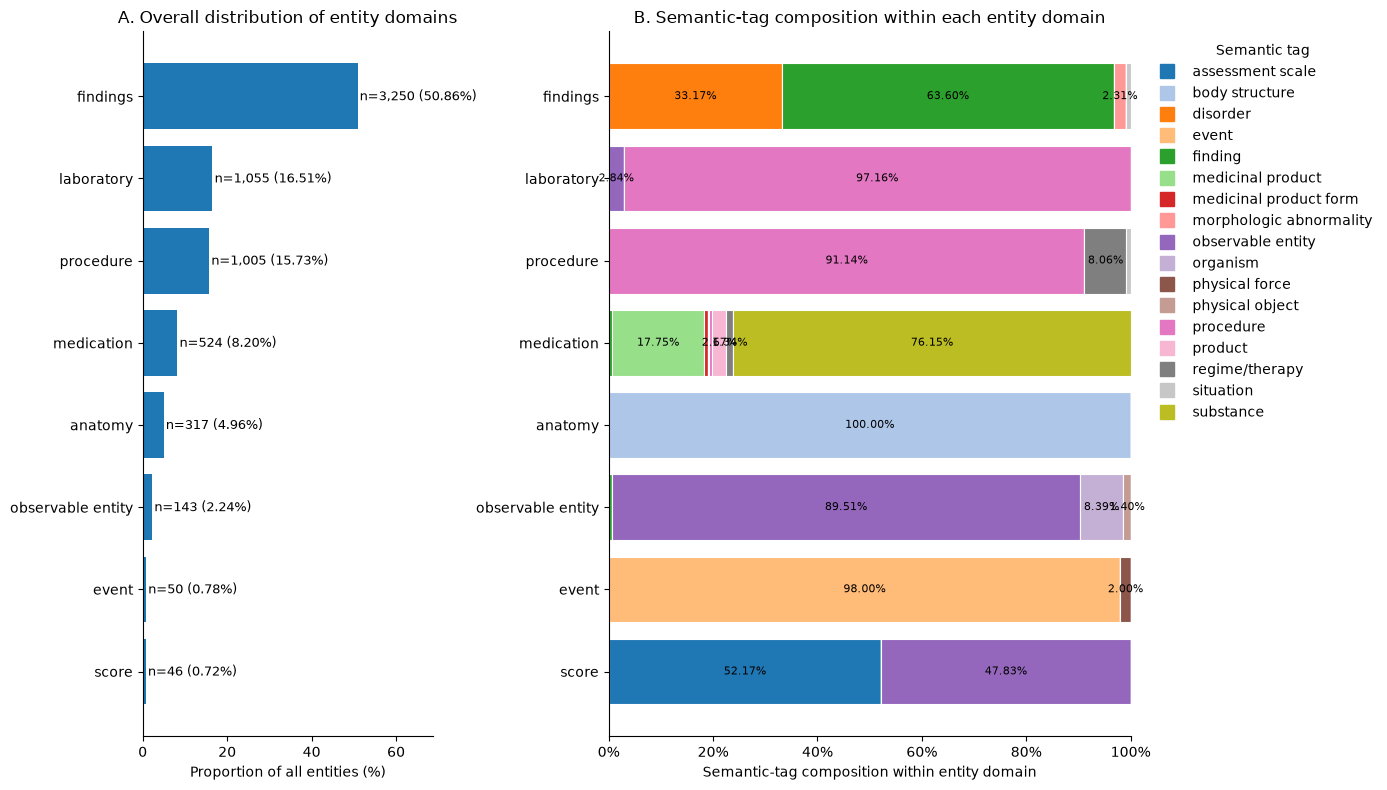

In [20]:
semantic_tag_per_label = (
    df.groupby('label')['semantic_tag']
      .value_counts()
      .unstack(fill_value=0)
      .reset_index()
)
entity_figure(semantic_tag_per_label, label_col="label")

In [21]:
dev_ids = {1800008, 1800051, 1800027, 1800044, 1800060,
           1800071, 1800092, 1800100, 1800102, 1800121,
           1800124, 1800140, 1800154, 1800169, 1800190,
           1800192, 1800196, 1800211, 1800214, 1800218}

In [ ]:
create_data_table(df, dev_ids)

In [25]:
display(semantic_tag_per_label)

semantic_tag,label,assessment scale,body structure,disorder,event,finding,medicinal product,medicinal product form,morphologic abnormality,observable entity,organism,physical force,physical object,procedure,product,regime/therapy,situation,substance
0,anatomy,0,317,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,event,0,0,0,49,0,0,0,0,0,0,1,0,0,0,0,0,0
2,findings,0,0,1078,0,2067,0,0,75,0,0,0,0,0,0,0,30,0
3,laboratory,0,0,0,0,0,0,0,0,30,0,0,0,1025,0,0,0,0
4,medication,0,0,0,0,3,93,4,0,0,1,0,0,3,14,7,0,399
5,observable entity,0,0,0,0,1,0,0,0,128,12,0,2,0,0,0,0,0
6,procedure,0,0,0,0,0,0,0,0,0,0,0,0,916,0,81,8,0
7,score,24,0,0,0,0,0,0,0,22,0,0,0,0,0,0,0,0
